In [1]:
# Titanic Survival Prediction
# Alfido Tech Machine Learning Internship
# Task 3

print("Titanic Survival Prediction Project")

Titanic Survival Prediction Project


In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load Titanic dataset

df = pd.read_csv('/content/titanic[1].csv')

# Display first five rows
print(df.head())

   PassengerId  Survived  Pclass  \
0          892         0       3   
1          893         1       3   
2          894         0       2   
3          895         0       3   
4          896         1       3   

                                           Name     Sex   Age  SibSp  Parch  \
0                              Kelly, Mr. James    male  34.5      0      0   
1              Wilkes, Mrs. James (Ellen Needs)  female  47.0      1      0   
2                     Myles, Mr. Thomas Francis    male  62.0      0      0   
3                              Wirz, Mr. Albert    male  27.0      0      0   
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  22.0      1      1   

    Ticket     Fare Cabin Embarked  
0   330911   7.8292   NaN        Q  
1   363272   7.0000   NaN        S  
2   240276   9.6875   NaN        Q  
3   315154   8.6625   NaN        S  
4  3101298  12.2875   NaN        S  


In [5]:
# Dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (418, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass    

Survived
0    266
1    152
Name: count, dtype: int64


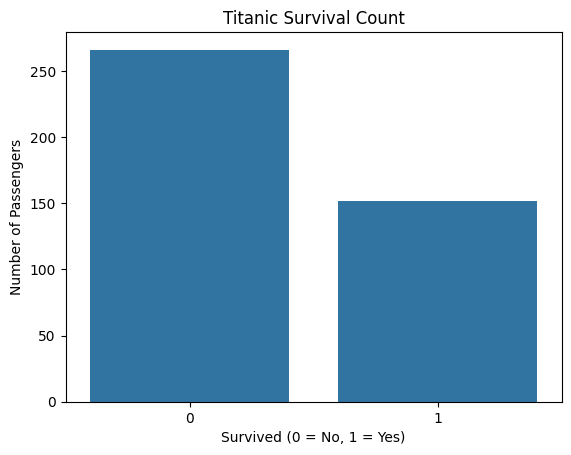

In [6]:
# Count survived and not survived passengers

print(df['Survived'].value_counts())

sns.countplot(data=df, x='Survived')

plt.title("Titanic Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

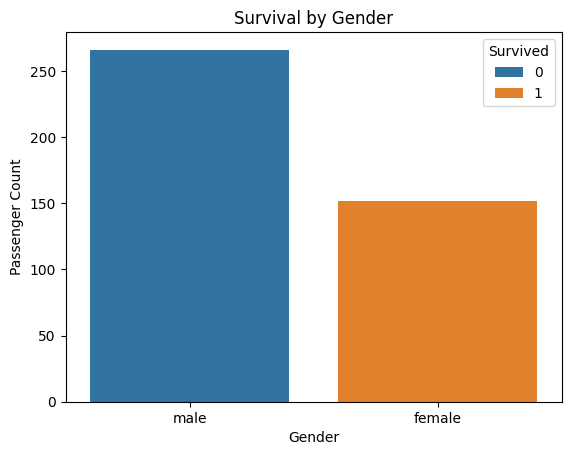

In [7]:
# Survival based on gender

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Passenger Count")

plt.show()

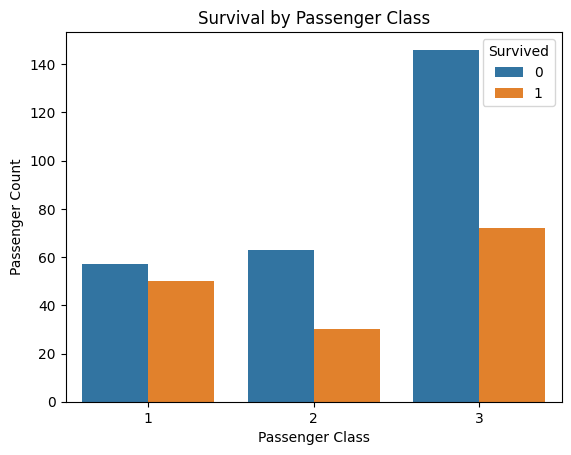

In [8]:
# Survival based on passenger class

sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Passenger Count")

plt.show()

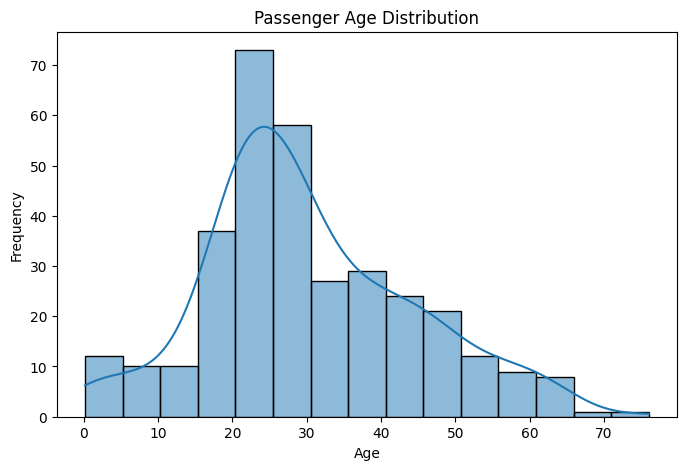

In [9]:
# Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Age', kde=True)

plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

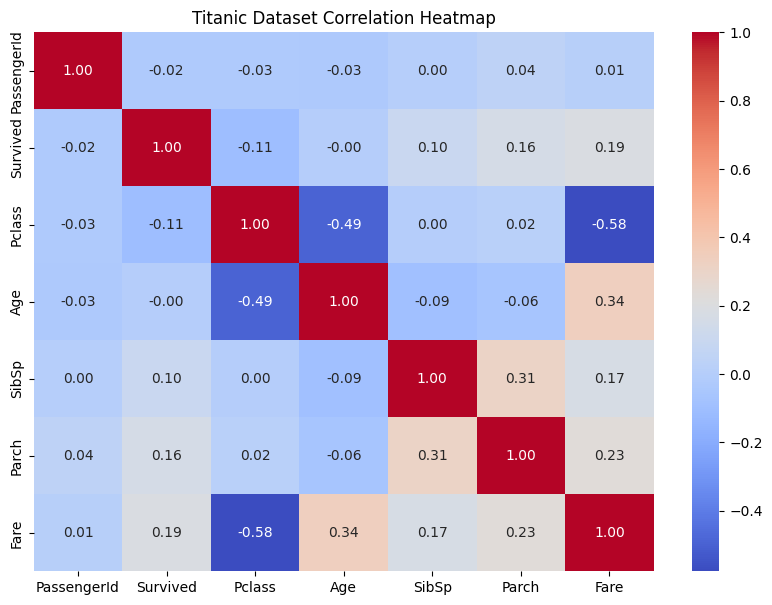

In [10]:
# Correlation between numerical features

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Titanic Dataset Correlation Heatmap")

plt.show()

In [11]:
# Create a copy of original dataset

titanic = df.copy()

print("Dataset copied successfully!")

Dataset copied successfully!


In [12]:
# Extract titles from passenger names

titanic['Title'] = titanic['Name'].str.extract(
    ' ([A-Za-z]+)\.',
    expand=False
)

print(titanic['Title'].value_counts())

Title
Mr        240
Miss       78
Mrs        72
Master     21
Col         2
Rev         2
Ms          1
Dr          1
Dona        1
Name: count, dtype: int64


<>:4: SyntaxWarning: invalid escape sequence '\.'
<>:4: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_554/4236419086.py:4: SyntaxWarning: invalid escape sequence '\.'
  ' ([A-Za-z]+)\.',


In [13]:
# Group uncommon titles

titanic['Title'] = titanic['Title'].replace(
    ['Lady', 'Countess', 'Capt', 'Col', 'Don',
     'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer',
     'Dona'],
    'Rare'
)

titanic['Title'] = titanic['Title'].replace(
    'Mlle', 'Miss'
)

titanic['Title'] = titanic['Title'].replace(
    'Ms', 'Miss'
)

titanic['Title'] = titanic['Title'].replace(
    'Mme', 'Mrs'
)

print(titanic['Title'].value_counts())

Title
Mr        240
Miss       79
Mrs        72
Master     21
Rare        6
Name: count, dtype: int64


In [15]:
# Create family size

titanic['FamilySize'] = (
    titanic['SibSp'] +
    titanic['Parch'] + 1
)

print(titanic[['SibSp', 'Parch', 'FamilySize']].head())
# Identify passengers travelling alone

titanic['IsAlone'] = (
    titanic['FamilySize'] == 1
).astype(int)

print(titanic[['FamilySize', 'IsAlone']].head())

   SibSp  Parch  FamilySize
0      0      0           1
1      1      0           2
2      0      0           1
3      0      0           1
4      1      1           3
   FamilySize  IsAlone
0           1        1
1           2        0
2           1        1
3           1        1
4           3        0


In [16]:
# Fill missing values

titanic['Age'] = titanic['Age'].fillna(
    titanic['Age'].median()
)

titanic['Embarked'] = titanic['Embarked'].fillna(
    titanic['Embarked'].mode()[0]
)

titanic['Fare'] = titanic['Fare'].fillna(
    titanic['Fare'].median()
)

print("Missing values after handling:")
print(titanic.isnull().sum())

Missing values after handling:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
Title            0
FamilySize       0
IsAlone          0
dtype: int64


In [17]:
# Drop unnecessary columns

titanic.drop(
    ['PassengerId', 'Name', 'Ticket', 'Cabin'],
    axis=1,
    inplace=True
)

print("Unnecessary columns removed!")
print(titanic.head())

Unnecessary columns removed!
   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked Title  \
0         0       3    male  34.5      0      0   7.8292        Q    Mr   
1         1       3  female  47.0      1      0   7.0000        S   Mrs   
2         0       2    male  62.0      0      0   9.6875        Q    Mr   
3         0       3    male  27.0      0      0   8.6625        S    Mr   
4         1       3  female  22.0      1      1  12.2875        S   Mrs   

   FamilySize  IsAlone  
0           1        1  
1           2        0  
2           1        1  
3           1        1  
4           3        0  


In [18]:
# Encode categorical variables

titanic = pd.get_dummies(
    titanic,
    columns=['Sex', 'Embarked', 'Title'],
    drop_first=True,
    dtype=int
)

print("Categorical encoding completed!")
print(titanic.head())

Categorical encoding completed!
   Survived  Pclass   Age  SibSp  Parch     Fare  FamilySize  IsAlone  \
0         0       3  34.5      0      0   7.8292           1        1   
1         1       3  47.0      1      0   7.0000           2        0   
2         0       2  62.0      0      0   9.6875           1        1   
3         0       3  27.0      0      0   8.6625           1        1   
4         1       3  22.0      1      1  12.2875           3        0   

   Sex_male  Embarked_Q  Embarked_S  Title_Miss  Title_Mr  Title_Mrs  \
0         1           1           0           0         1          0   
1         0           0           1           0         0          1   
2         1           1           0           0         1          0   
3         1           0           1           0         1          0   
4         0           0           1           0         0          1   

   Title_Rare  
0           0  
1           0  
2           0  
3           0  
4           0  


In [19]:
# Separate input features and target

X = titanic.drop('Survived', axis=1)

y = titanic['Survived']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Pclass   Age  SibSp  Parch     Fare  FamilySize  IsAlone  Sex_male  \
0       3  34.5      0      0   7.8292           1        1         1   
1       3  47.0      1      0   7.0000           2        0         0   
2       2  62.0      0      0   9.6875           1        1         1   
3       3  27.0      0      0   8.6625           1        1         1   
4       3  22.0      1      1  12.2875           3        0         0   

   Embarked_Q  Embarked_S  Title_Miss  Title_Mr  Title_Mrs  Title_Rare  
0           1           0           0         1          0           0  
1           0           1           0         0          1           0  
2           1           0           0         1          0           0  
3           0           1           0         1          0           0  
4           0           1           0         0          1           0  

Target:
0    0
1    1
2    0
3    0
4    1
Name: Survived, dtype: int64


In [20]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (334, 14)
Testing data: (84, 14)


In [21]:
# Feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Classification models imported successfully!")

Classification models imported successfully!


In [23]:
# Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [24]:
# Decision Tree Classifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


In [25]:
# Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [26]:
# Compare actual and predicted survival

print("Actual Survival:")
print(y_test.head(10).values)

print("\nLogistic Regression Predictions:")
print(lr_predictions[:10])

print("\nDecision Tree Predictions:")
print(dt_predictions[:10])

print("\nRandom Forest Predictions:")
print(rf_predictions[:10])

Actual Survival:
[1 1 0 1 0 0 0 1 1 1]

Logistic Regression Predictions:
[1 1 0 1 0 0 0 1 1 1]

Decision Tree Predictions:
[1 1 0 1 0 0 0 1 1 1]

Random Forest Predictions:
[1 1 0 1 0 0 0 1 1 1]


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [28]:
models = {
    "Logistic Regression": lr_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression       1.0        1.0     1.0       1.0
1        Decision Tree       1.0        1.0     1.0       1.0
2        Random Forest       1.0        1.0     1.0       1.0


In [29]:
print("Logistic Regression Report:")
print(classification_report(y_test, lr_predictions))

print("\nDecision Tree Report:")
print(classification_report(y_test, dt_predictions))

print("\nRandom Forest Report:")
print(classification_report(y_test, rf_predictions))

Logistic Regression Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       1.00      1.00      1.00        31

    accuracy                           1.00        84
   macro avg       1.00      1.00      1.00        84
weighted avg       1.00      1.00      1.00        84


Decision Tree Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       1.00      1.00      1.00        31

    accuracy                           1.00        84
   macro avg       1.00      1.00      1.00        84
weighted avg       1.00      1.00      1.00        84


Random Forest Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       1.00      1.00      1.00        31

    accuracy                           1.00        84
   macro avg       1.00      1.00      1.00        84


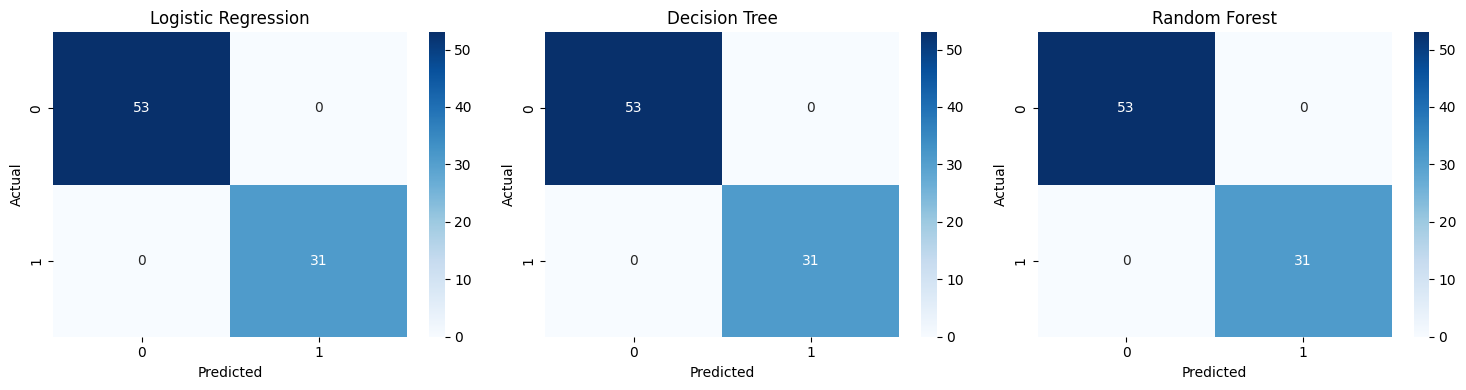

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

predictions_list = [
    lr_predictions,
    dt_predictions,
    rf_predictions
]

model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

for ax, predictions, name in zip(
    axes, predictions_list, model_names
):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

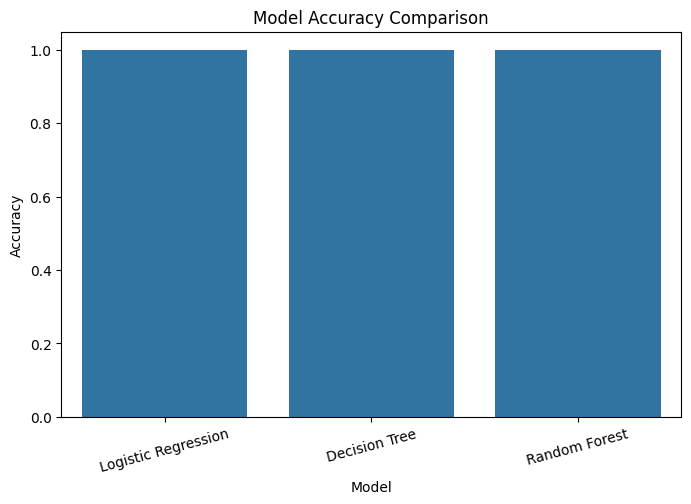

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)

plt.show()

In [32]:
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [33]:
# Feature importance analysis

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

       Feature  Importance
7     Sex_male    0.421887
11    Title_Mr    0.292815
10  Title_Miss    0.130689
12   Title_Mrs    0.070018
1          Age    0.021256
4         Fare    0.015064
5   FamilySize    0.012345
3        Parch    0.007890
6      IsAlone    0.007484
0       Pclass    0.006459
2        SibSp    0.005161
13  Title_Rare    0.003940
8   Embarked_Q    0.003115
9   Embarked_S    0.001878


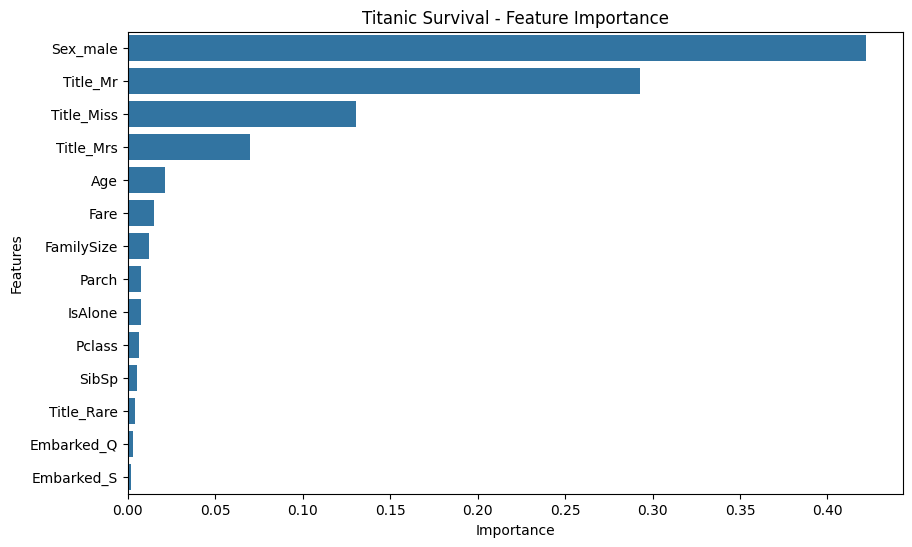

In [34]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Titanic Survival - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

In [35]:
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [36]:
# Select the best model

best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(), 'Model'
]

print("Best Model:", best_model_name)

if best_model_name == "Logistic Regression":
    best_model = lr_model
elif best_model_name == "Decision Tree":
    best_model = dt_model
else:
    best_model = rf_model

print("Best model selected successfully!")

Best Model: Logistic Regression
Best model selected successfully!


In [37]:
import joblib

# Save model and preprocessing information

model_data = {
    'model': best_model,
    'scaler': scaler if best_model_name == "Logistic Regression" else None,
    'feature_columns': X.columns.tolist(),
    'model_name': best_model_name
}

joblib.dump(model_data, "best_titanic_model.pkl")

print("Best Titanic model saved successfully!")

Best Titanic model saved successfully!


In [38]:
# Load saved model

loaded_data = joblib.load("best_titanic_model.pkl")

loaded_model = loaded_data['model']

if loaded_data['scaler'] is not None:
    test_data = X_test_scaled[:5]
else:
    test_data = X_test.iloc[:5]

predictions = loaded_model.predict(test_data)

print("Predicted Survival:", predictions)
print("Actual Survival:", y_test.iloc[:5].values)

Predicted Survival: [1 1 0 1 0]
Actual Survival: [1 1 0 1 0]


In [39]:
from google.colab import files

files.download("best_titanic_model.pkl")
files.download("model_comparison.csv")
files.download("feature_importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>